# Section 3.4: Logistic Regression

**Topics:** Sigmoid/logistic function, Binary classification probabilities, Logistic regression fitting and interpretation

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/drive/1_R7_YmcwetrGctDuci97gWM98gXSRpb_?usp=sharing)

In [63]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, roc_auc_score, classification_report

np.set_printoptions(precision=4, suppress=True)


## Sigmoid/logistic function

Sigmoid and Logistic functions allow us to connect real-world numerical values to probabilities, giving us an understanding of how independent variables change with binary outcomes. In this case, we demonstrate a sigmoid funciton and plot to show this relationship.

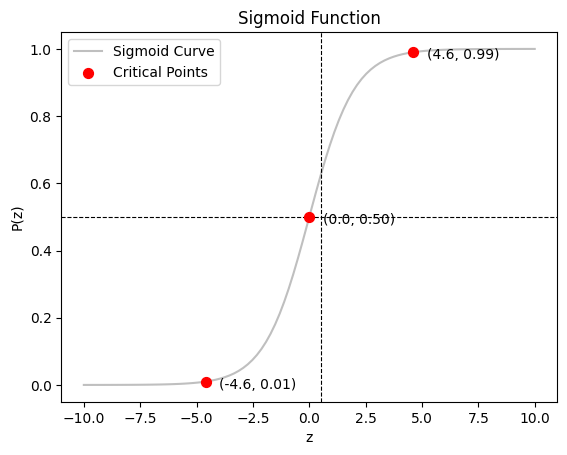

In [64]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

z_curve = np.linspace(-10, 10, 100)
plt.plot(z_curve, sigmoid(z_curve), color="grey", alpha=0.5, label="Sigmoid Curve")

z_points = np.array([-4.6,0,4.6])
plt.scatter(z_points, sigmoid(z_points), color="red", s=50, zorder=5, label="Critical Points")

for x in z_points:
  y = sigmoid(x)
  plt.annotate(f"({x}, {y:.2f})", (x, y), textcoords="offset points", xytext=(10,-5), ha="left")

plt.axhline(0.5, color="black", linewidth=0.8, linestyle="--")
plt.axvline(0.5, color="black", linewidth=0.8, linestyle="--")
plt.xlabel("z")
plt.ylabel("P(z)")
plt.title("Sigmoid Function")
plt.legend()
plt.show()

## Binary classification probabilities

Binary classification uses probabilities to determine the outcome of a predicted label, such as Yes/No, 0/1, or any other outcome similarity. In this case, we can measure how well a model can train for binary classification cases, using binary classification.

In [65]:
# Make a Classification Sampling Chart
X, y = make_classification(n_samples=10000, n_features=2, n_redundant=0, n_informative=2,
                           n_clusters_per_class=1, class_sep=1.2, random_state=422)
# Train and Test Samples
X_train, X_test, Y_train, Y_test = train_test_split(X, y, test_size=0.2, random_state=422)
model = LogisticRegression()
model.fit(X_train, Y_train)
pred = model.predict(X_test)
proba = model.predict_proba(X_test)[:, 1]
# Configure Results:
print("Coefficients:", model.coef_)
print("Intercept:", model.intercept_)
print("--------Testing Results--------")
print("Test accuracy:", accuracy_score(Y_test, pred))
print(f"ROC-AUC Accuracy: {roc_auc_score(Y_test, proba):.4f}")
print("Confusion matrix:\n", confusion_matrix(Y_test, pred))
print("Classification Report\n", classification_report(Y_test, pred))
# Heat Map Plot based on Results
x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200),
                     np.linspace(y_min, y_max, 200))
# Set up Grid Plots for Graphing
grid_points = np.c_[xx.ravel(), yy.ravel()]
grid_pred = model.predict_proba(grid_points)[:, 1]
grid_pred = grid_pred.reshape(xx.shape)

Coefficients: [[3.787  5.3592]]
Intercept: [2.5483]
--------Testing Results--------
Test accuracy: 0.9895
ROC-AUC Accuracy: 0.9932
Confusion matrix:
 [[984  16]
 [  5 995]]
Classification Report
               precision    recall  f1-score   support

           0       0.99      0.98      0.99      1000
           1       0.98      0.99      0.99      1000

    accuracy                           0.99      2000
   macro avg       0.99      0.99      0.99      2000
weighted avg       0.99      0.99      0.99      2000



## Logistic regression fitting and interpretation

Logistic Regression Fitting and Interpretation uses probabilities and regressional values to understand the relationships between categorical dependent variables and indepdendent variables. In this case, we can graph the probability surface to show this relationship.

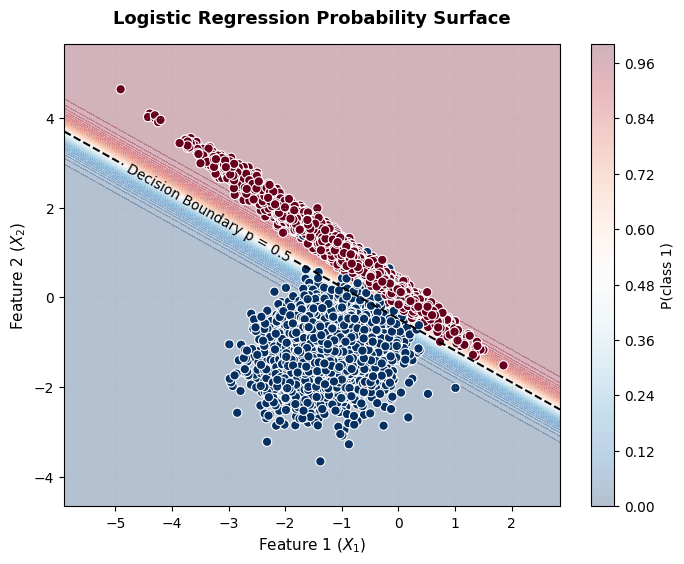

In [66]:
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200),
                     np.linspace(y_min, y_max, 200))
grid = np.c_[xx.ravel(), yy.ravel()]
zz = model.predict_proba(grid)[:, 1].reshape(xx.shape)

fig, ax = plt.subplots(figsize=(8, 6), dpi=100)

contour = ax.contourf(xx, yy, zz, levels=50, cmap="RdBu_r", alpha=0.3)
cbar = fig.colorbar(contour, ax=ax, label="P(class 1)")
cbar.ax.tick_params(labelsize=10)

boundary = ax.contour(xx, yy, zz, levels=[0.5], colors="black", linestyles="dashed")
ax.clabel(boundary, inline=True, fmt={0.5: "Decision Boundary p = 0.5"}, fontsize=10, colors="black")

scatter = ax.scatter(X[:, 0], X[:, 1], c=y, cmap="RdBu_r", edgecolors="white", linewidths=0.8, s=45)

ax.set_title("Logistic Regression Probability Surface", fontsize=13, fontweight="bold", pad=15)
ax.set_xlabel("Feature 1 ($X_1$)", fontsize=11)
ax.set_ylabel("Feature 2 ($X_2$)", fontsize=11)
ax.set_xlim(x_min, x_max)
ax.set_ylim(y_min, y_max)
ax.grid(True, linestyle=":", alpha=0.4, zorder=0)

plt.show()